# Models Evaluation

In [1]:
from pathlib import Path
import sys

project_root = Path.cwd()
if not (project_root / 'main.py').exists():
    project_root = project_root.parent
sys.path.insert(0, str(project_root))

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split

from config import config
from evaluation import compare_models

## Данные и разбиение

In [2]:
data = pd.read_csv(config.paths.train_data)

X = data.drop(columns=[config.general.target])
y = data[config.general.target]

X.head()

,PassengerId,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=config.split.test_size,
    random_state=config.general.seed,
    stratify=y
)

## Сравнение моделей

In [4]:
results = compare_models(X_train, y_train, config)
results

,Model,CV Mean,CV Std
0,catboost,0.839606,0.044812
1,random_forest,0.833154,0.045630
2,xgboost,0.826754,0.037926
3,knn,0.825064,0.038203
4,decision_tree,0.810727,0.034848
5,logistic_regression,0.802791,0.045519


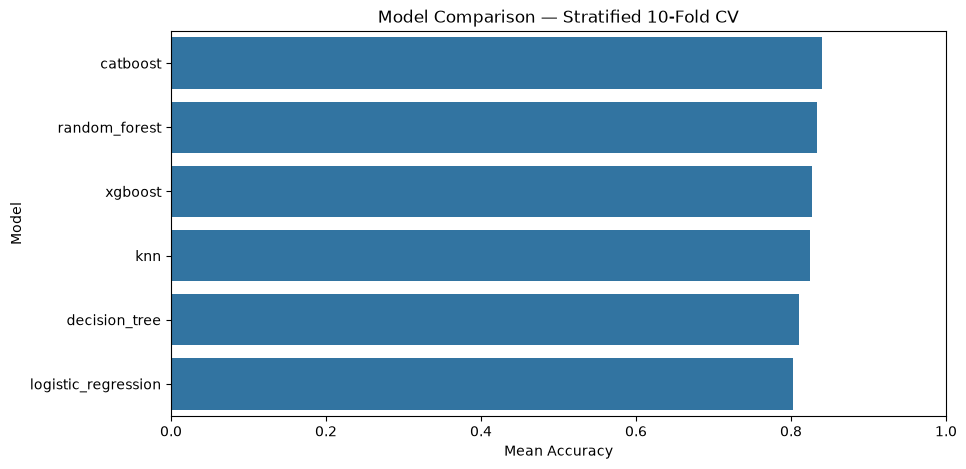

In [5]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=results,
    x='CV Mean',
    y='Model',
)

plt.title('Model Comparison — Stratified 10-Fold CV')
plt.xlabel('Mean Accuracy')
plt.ylabel('Model')
plt.xlim(0, 1)
plt.show()

Базово catboost показывает наивысшую точность

## Deep Learning

In [6]:
import torch
from dl import prepare_data, MLP, train_model

In [10]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'

X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=config.split.test_size,
    random_state=config.general.seed,
    stratify=y
)

train_dataset, val_dataset, _, _ = prepare_data(X_train, X_val, y_train, y_val)

In [11]:
model = MLP(
    input_dim=train_dataset.tensors[0].shape[1]
).to(device)

best_model_state, _, _ = train_model(model, train_dataset, val_dataset, device)

model.load_state_dict(best_model_state)

Epoch 1/100 | Train Loss: 0.6427 | Val Loss: 0.6050 | Val Accuracy: 0.6493
Epoch 2/100 | Train Loss: 0.5768 | Val Loss: 0.5352 | Val Accuracy: 0.7612
Epoch 3/100 | Train Loss: 0.5119 | Val Loss: 0.4774 | Val Accuracy: 0.8134
Epoch 4/100 | Train Loss: 0.4627 | Val Loss: 0.4407 | Val Accuracy: 0.8172
Epoch 5/100 | Train Loss: 0.4347 | Val Loss: 0.4236 | Val Accuracy: 0.8060
Epoch 6/100 | Train Loss: 0.4215 | Val Loss: 0.4176 | Val Accuracy: 0.8097
Epoch 7/100 | Train Loss: 0.4144 | Val Loss: 0.4155 | Val Accuracy: 0.8172
Epoch 8/100 | Train Loss: 0.4094 | Val Loss: 0.4140 | Val Accuracy: 0.8172
Epoch 9/100 | Train Loss: 0.4056 | Val Loss: 0.4140 | Val Accuracy: 0.8134
Epoch 10/100 | Train Loss: 0.4008 | Val Loss: 0.4134 | Val Accuracy: 0.8134
Epoch 11/100 | Train Loss: 0.3983 | Val Loss: 0.4133 | Val Accuracy: 0.8209
Epoch 12/100 | Train Loss: 0.3935 | Val Loss: 0.4133 | Val Accuracy: 0.8246
Epoch 13/100 | Train Loss: 0.3933 | Val Loss: 0.4150 | Val Accuracy: 0.8284
Epoch 14/100 | Train 

<All keys matched successfully>

## Подбор гиперпараметров

In [12]:
from tuning import tune_all_models

In [13]:
results, best_models = tune_all_models(
    X_train,
    y_train,
    config
)

results


Tuning logistic_regression...
Fitting 5 folds for each of 5 candidates, totalling 25 fits

Tuning knn...
Fitting 5 folds for each of 24 candidates, totalling 120 fits

Tuning decision_tree...
Fitting 5 folds for each of 27 candidates, totalling 135 fits

Tuning random_forest...
Fitting 5 folds for each of 27 candidates, totalling 135 fits

Tuning xgboost...
Fitting 5 folds for each of 72 candidates, totalling 360 fits

Tuning catboost...
Fitting 5 folds for each of 72 candidates, totalling 360 fits


,Model,CV Mean,CV Std,Best Params
0,catboost,0.839548,0.031396,"{'model__depth': 4, 'model__iterations': 500, ..."
1,xgboost,0.837935,0.022536,"{'model__learning_rate': 0.05, 'model__max_dep..."
2,random_forest,0.833135,0.027595,"{'model__max_depth': 5, 'model__min_samples_le..."
3,knn,0.817110,0.028798,"{'model__n_neighbors': 15, 'model__p': 2, 'mod..."
4,decision_tree,0.815497,0.036491,"{'model__max_depth': 3, 'model__min_samples_le..."
5,logistic_regression,0.804271,0.028365,{'model__C': 0.01}


In [14]:
results.loc[
    results['Model'] == 'catboost',
    'Best Params'
].iloc[0]

{'model__depth': 4,
 'model__iterations': 500,
 'model__l2_leaf_reg': 3,
 'model__learning_rate': 0.01}

После настройки гиперпараметров catboost продолжает показывать наивысшую точность, можем использовать его лучшую конфигурацию параметров для построения решения

## Настройка DL модели

In [15]:
from torch.utils.data import DataLoader
from torch import nn
from dl import evaluate

In [16]:
experiments = {
    'Baseline': {
        'use_batchnorm': False,
        'use_dropout': False,
    },
    'BatchNorm': {
        'use_batchnorm': True,
        'use_dropout': False,
    },
    'Dropout': {
        'use_batchnorm': False,
        'use_dropout': True,
    },
    'BatchNorm + Dropout': {
        'use_batchnorm': True,
        'use_dropout': True,
    },
}

In [19]:

def run_experiment(name, model_params):
    model = MLP(
        input_dim=train_dataset.tensors[0].shape[1],
        dropout_rate=config.dl.dropout_rate,
        **model_params
    ).to(device)

    best_model_state, history, best_epoch = train_model(
        model,
        train_dataset,
        val_dataset,
        device
    )

    model.load_state_dict(best_model_state)

    val_loader = DataLoader(
        val_dataset,
        batch_size=config.dl.batch_size,
        shuffle=False
    )

    criterion = nn.BCEWithLogitsLoss()

    metrics = evaluate(
        model,
        val_loader,
        criterion,
        device
    )

    result = {
        'Model': name,
        'Best Epoch': best_epoch,
        'Val Loss': metrics['loss'],
        'Val Accuracy': metrics['accuracy'],
    }

    for epoch_metrics in history:
        epoch_metrics['Experiment'] = name

    return result, history


In [20]:
results = []
histories = []

for name, params in experiments.items():
    print(f'\nTraining {name}')

    result, history = run_experiment(name, params)

    results.append(result)
    histories.extend(history)

results_df = pd.DataFrame(results)
history_df = pd.DataFrame(histories)

results_df.sort_values(
    'Val Accuracy',
    ascending=False
)


Training Baseline
Epoch 1/100 | Train Loss: 0.6462 | Val Loss: 0.6091 | Val Accuracy: 0.7910
Epoch 2/100 | Train Loss: 0.5755 | Val Loss: 0.5360 | Val Accuracy: 0.7985
Epoch 3/100 | Train Loss: 0.5042 | Val Loss: 0.4631 | Val Accuracy: 0.8209
Epoch 4/100 | Train Loss: 0.4485 | Val Loss: 0.4264 | Val Accuracy: 0.8321
Epoch 5/100 | Train Loss: 0.4271 | Val Loss: 0.4171 | Val Accuracy: 0.8209
Epoch 6/100 | Train Loss: 0.4164 | Val Loss: 0.4130 | Val Accuracy: 0.8209
Epoch 7/100 | Train Loss: 0.4099 | Val Loss: 0.4118 | Val Accuracy: 0.8246
Epoch 8/100 | Train Loss: 0.4073 | Val Loss: 0.4121 | Val Accuracy: 0.8209
Epoch 9/100 | Train Loss: 0.4017 | Val Loss: 0.4108 | Val Accuracy: 0.8246
Epoch 10/100 | Train Loss: 0.3982 | Val Loss: 0.4117 | Val Accuracy: 0.8246
Epoch 11/100 | Train Loss: 0.3955 | Val Loss: 0.4109 | Val Accuracy: 0.8209
Epoch 12/100 | Train Loss: 0.3940 | Val Loss: 0.4129 | Val Accuracy: 0.8246
Epoch 13/100 | Train Loss: 0.3895 | Val Loss: 0.4135 | Val Accuracy: 0.8284
Ep

,Model,Best Epoch,Val Loss,Val Accuracy
1,BatchNorm,8,0.418398,0.832090
0,Baseline,9,0.410758,0.824627
2,Dropout,20,0.413635,0.820896
3,BatchNorm + Dropout,12,0.421235,0.817164


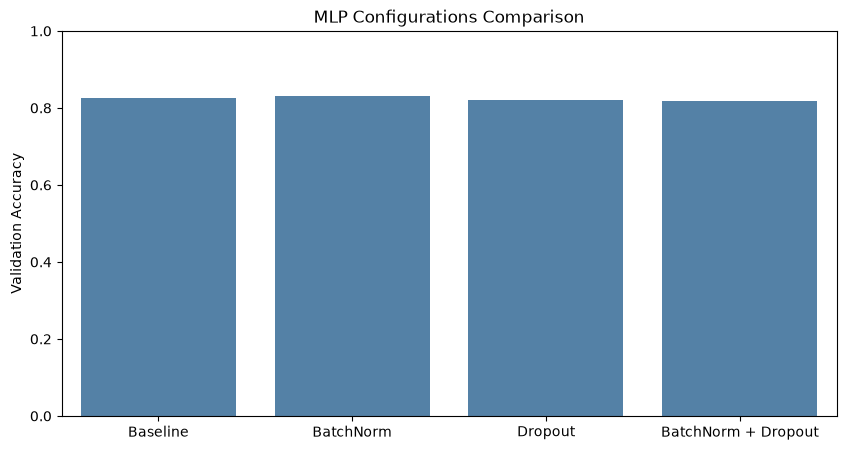

In [21]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=results_df,
    x='Model',
    y='Val Accuracy',
    color='steelblue'
)

plt.title('MLP Configurations Comparison')
plt.ylabel('Validation Accuracy')
plt.xlabel('')
plt.ylim(0, 1)
plt.show()

В целом конфигурации показывают практически одинаковую точность на валидационной выборке с небольшим премуществом BatchNorm

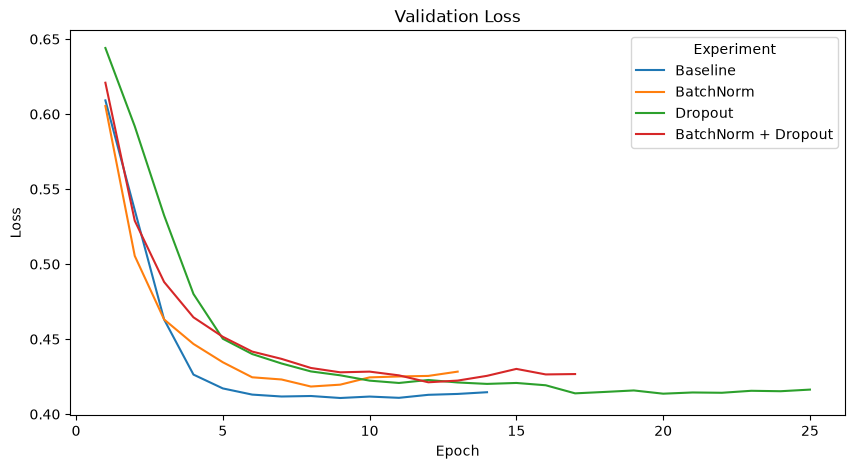

In [22]:
plt.figure(figsize=(10, 5))

sns.lineplot(
    data=history_df,
    x='epoch',
    y='val_loss',
    hue='Experiment'
)

plt.title('Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.show()

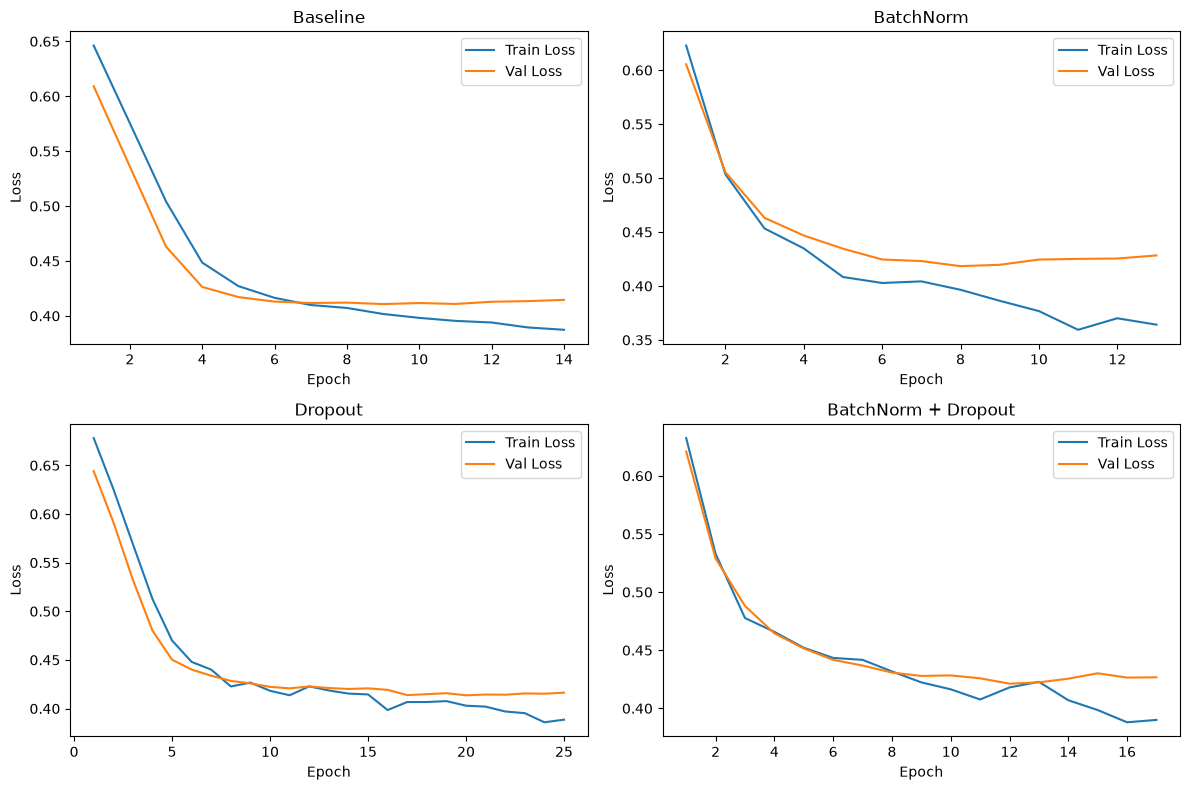

In [24]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for ax, name in zip(axes.flat, experiments):
    subset = history_df[
        history_df['Experiment'] == name
    ]

    ax.plot(
        subset['epoch'],
        subset['train_loss'],
        label='Train Loss'
    )

    ax.plot(
        subset['epoch'],
        subset['val_loss'],
        label='Val Loss'
    )

    ax.set_title(name)
    ax.set_xlabel('Epoch')
    ax.set_ylabel('Loss')
    ax.legend()

plt.tight_layout()
plt.show()

Модель с BatchNorm сильнее всего переобучается (начиная уже с 7 эпохи). Наименьшее переобучение у модели с Dropout